# 03. MaxPool2d와 stride 2 Conv 비교
`02_응용/03_downsample.py`의 동일한 입력에 두 downsampling 연산을 적용하고 **출력 shape와 학습 파라미터 수**를 비교합니다.

## 0. 작업 전 준비사항
PyTorch, pandas, matplotlib이 설치된 Python 커널에서 **Run All(모두 실행)**로 실행합니다. 난수 텐서를 사용하므로 CPU로 충분하며 데이터 다운로드가 필요하지 않습니다.

원본 Python 파일은 수정하지 않습니다. 비교 CSV와 그림은 `20261102/02_응용/docs/outputs`에 저장합니다. 노트북의 그림은 실행 결과에도 포함합니다.

In [1]:
%matplotlib inline
from pathlib import Path
import torch
from torch import nn
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle

torch.manual_seed(42)
torch.set_num_threads(1)
cwd = Path.cwd().resolve()
day_root = next((candidate for parent in (cwd, *cwd.parents)
                 for candidate in (parent / "20261102", parent)
                 if (candidate / "02_응용" / "03_downsample.py").is_file()), None)
if day_root is None:
    raise FileNotFoundError("이 저장소 안에서 노트북을 실행하세요.")
out = day_root / "02_응용" / "docs" / "outputs"
out.mkdir(parents=True, exist_ok=True)
print("PyTorch:", torch.__version__)
print("실습 장치: CPU")

PyTorch: 2.14.0+cu130
실습 장치: CPU


## 1. 각 연산을 입력에 적용하기
입력 `x`는 NCHW `(4, 8, 32, 32)`입니다. 배치에 이미지 또는 특징 맵 묶음 4개가 있으며, 각각 채널 8개와 공간 크기 32×32를 가집니다.

```python
for name, layer in operations.items():
    y = layer(x)
```

`name`은 결과를 구분하는 문자열이고 `layer`는 실행할 층입니다. `layer(x)`가 해당 층의 순전파를 수행해 결과 텐서를 반환합니다. 두 층 모두 동일한 원본 `x`에 적용하며, Pooling 결과를 Conv에 이어 넣는 구성이 아닙니다.

| 설정 | MaxPool2d | stride 2 Conv |
| --- | --- | --- |
| 생성 코드 | `nn.MaxPool2d(2)` | `nn.Conv2d(8, 8, 3, stride=2, padding=1)` |
| 커널 크기 | 2×2 | 3×3 |
| stride | 기본값이 kernel_size와 같아 2 | 명시적으로 2 |
| padding | 기본값 0 | 1 |
| 계산 | 채널별 각 영역의 최댓값 선택 | 모든 입력 채널의 가중합에 편향 추가 |
| 학습 대상 | 없음 | 필터 가중치와 편향 |

In [2]:
# 원본 파일과 같은 seed, 입력, 층 설정을 사용합니다.
torch.manual_seed(42)
x = torch.rand(4, 8, 32, 32)
operations = {
    "pool": nn.MaxPool2d(2),
    "conv_stride2": nn.Conv2d(8, 8, 3, stride=2, padding=1),
}
rows = []
outputs = {}
for name, layer in operations.items():
    with torch.no_grad():
        y = layer(x)
    outputs[name] = y
    rows.append(dict(method=name, shape=str(tuple(y.shape)),
                     params=sum(p.numel() for p in layer.parameters())))
results = pd.DataFrame(rows)
print("입력 shape:", tuple(x.shape))
print(results.to_string(index=False))
results.to_csv(out / "downsample_comparison.csv", index=False)

assert outputs["pool"].shape == outputs["conv_stride2"].shape == (4, 8, 16, 16)
assert rows[0]["params"] == 0
assert rows[1]["params"] == 584
# 2×2 블록별 최댓값과 실제 Pooling 출력을 비교합니다.
expected_pool = x.reshape(4, 8, 16, 2, 16, 2).amax(dim=(3, 5))
assert torch.equal(outputs["pool"], expected_pool)
print("출력 shape·파라미터 수·Pooling 최댓값 검증 완료")

입력 shape: (4, 8, 32, 32)
      method          shape  params
        pool (4, 8, 16, 16)       0
conv_stride2 (4, 8, 16, 16)     584
출력 shape·파라미터 수·Pooling 최댓값 검증 완료


## 2. 출력 shape와 파라미터 수가 결정되는 이유
### 출력 shape: 이번 설정에서는 동일
기본 dilation=1, Pooling의 기본 ceil_mode=False일 때 각 공간 축의 출력 크기는 다음과 같습니다.

$$L_{out}=\left\lfloor\frac{L+2P-(K-1)-1}{S}\right\rfloor+1$$

- MaxPool2d: `floor((32 - 2) / 2) + 1 = 16`
- Conv2d: `floor((32 + 2 - 3) / 2) + 1 = 16`

두 층 모두 배치 크기 4를 유지합니다. Pooling은 채널별로 독립적으로 계산하여 채널 수 8도 유지합니다. Conv의 출력 채널이 8인 이유는 `out_channels=8`로 지정했기 때문입니다. 따라서 두 출력은 모두 `(4, 8, 16, 16)`이며, 출력 원소 수는 입력의 1/4입니다. 다른 커널·padding·입력 크기에서는 결과를 다시 계산해야 합니다.

### 파라미터 수: 0개와 584개
MaxPool2d는 최댓값을 선택하는 고정 규칙이어서 학습 파라미터가 없습니다.

Conv2d는 기본 `groups=1`, `bias=True`로 생성됩니다.

- 필터 shape: `(출력 채널, 입력 채널, 커널 높이, 커널 너비) = (8, 8, 3, 3)`
- 가중치 수: `8 × 8 × 3 × 3 = 576`
- 편향 수: 출력 채널마다 1개씩 `8`
- 총 학습 파라미터: `576 + 8 = 584`

파라미터 수는 배치 크기와 이미지 높이·너비가 바뀌어도 그대로입니다. 파라미터가 0개라는 것은 연산이 없다는 뜻이 아니며, Pooling도 영역 내 값을 비교합니다. 또한 MaxPool2d는 역전파 시 선택된 최댓값 위치로 기울기를 전달할 수 있습니다.

## 3. 시각화로 비교하기
### 작은 숫자 배열에서 MaxPool2d 확인
4×4 단일 채널 입력에 2×2 Pooling을 적용합니다. 색 테두리는 서로 다른 네 영역이고, 출력의 각 숫자는 해당 영역의 최댓값입니다.

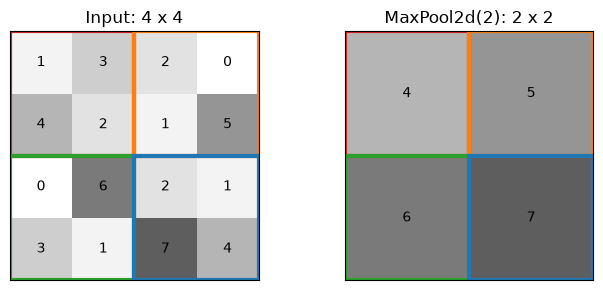

In [3]:
small = torch.tensor([[1., 3., 2., 0.],
                      [4., 2., 1., 5.],
                      [0., 6., 2., 1.],
                      [3., 1., 7., 4.]])
pooled = nn.MaxPool2d(2)(small[None, None])[0, 0]
fig, axes = plt.subplots(1, 2, figsize=(7, 3))
colors = ["tab:red", "tab:orange", "tab:green", "tab:blue"]
for ax, values, title in zip(axes, [small.numpy(), pooled.numpy()],
                            ["Input: 4 x 4", "MaxPool2d(2): 2 x 2"]):
    ax.imshow(values, cmap="Greys", vmin=0, vmax=10)
    for h in range(values.shape[0]):
        for w in range(values.shape[1]):
            ax.text(w, h, f"{values[h, w]:.0f}", ha="center", va="center")
    ax.set_title(title)
    ax.set_xticks([])
    ax.set_yticks([])
for i, color in enumerate(colors):
    h, w = divmod(i, 2)
    axes[0].add_patch(Rectangle((w * 2 - .5, h * 2 - .5), 2, 2,
                               fill=False, edgecolor=color, linewidth=3))
    axes[1].add_patch(Rectangle((w - .5, h - .5), 1, 1,
                               fill=False, edgecolor=color, linewidth=3))
fig.tight_layout()
fig.savefig(out / "downsample_pool_example.png", dpi=140)
plt.show()
plt.close(fig)

### 同一 입력에 적용한 특징 맵
첫 배치의 채널 0을 공통 색 범위로 표시합니다. Pooling 출력의 채널 0은 입력 채널 0의 각 2×2 영역에서 최댓값을 선택한 결과입니다. Conv 출력의 채널 0은 **입력 채널 8개 전체**를 조합한 결과이므로 단순한 원본 채널 축소본이 아닙니다.

여기서 Conv는 학습 전 무작위 가중치입니다. 그림은 계산 방식과 해상도를 보여 주며 성능이나 학습된 특징의 품질을 비교하지 않습니다.

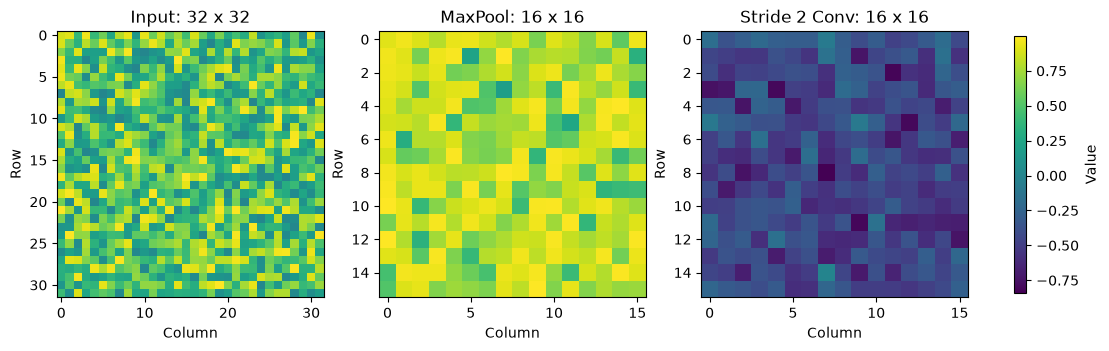

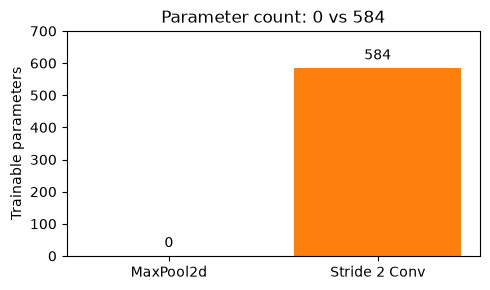

In [4]:
maps = [x[0, 0], outputs["pool"][0, 0], outputs["conv_stride2"][0, 0]]
vmin = min(t.min().item() for t in maps)
vmax = max(t.max().item() for t in maps)
fig, axes = plt.subplots(1, 3, figsize=(11, 3.5), constrained_layout=True)
for ax, tensor, title in zip(axes, maps, ["Input: 32 x 32", "MaxPool: 16 x 16", "Stride 2 Conv: 16 x 16"]):
    im = ax.imshow(tensor.numpy(), vmin=vmin, vmax=vmax, cmap="viridis", interpolation="nearest")
    ax.set_title(title)
    ax.set_xlabel("Column")
    ax.set_ylabel("Row")
fig.colorbar(im, ax=axes, label="Value", shrink=0.8)
fig.savefig(out / "downsample_feature_maps.png", dpi=140)
plt.show()
plt.close(fig)

fig, ax = plt.subplots(figsize=(5, 3))
bars = ax.bar(["MaxPool2d", "Stride 2 Conv"], results["params"], color=["tab:blue", "tab:orange"])
ax.bar_label(bars, padding=4)
ax.set_ylabel("Trainable parameters")
ax.set_ylim(0, 700)
ax.set_title("Parameter count: 0 vs 584")
fig.tight_layout()
fig.savefig(out / "downsample_parameters.png", dpi=140)
plt.show()
plt.close(fig)

## 4. 결과 해석 및 추가 실험
| 연산 | 출력 shape | 학습 파라미터 | 채널 처리 |
| --- | --- | --- | --- |
| MaxPool2d(2) | `(4, 8, 16, 16)` | 0 | 각 채널에서 독립적으로 최댓값 선택 |
| Conv2d(8, 8, 3, stride=2, padding=1) | `(4, 8, 16, 16)` | 584 | 입력 8개 채널을 조합해 출력 8개 채널 생성 |

두 층은 이 설정에서 같은 공간 해상도로 downsampling하지만 출력값과 학습 가능 여부가 다릅니다. Pooling은 고정된 최댓값 선택으로 해상도를 줄이고, stride Conv는 학습 가능한 특징 변환과 공간 축소를 함께 수행합니다. 더 많은 파라미터가 항상 더 좋은 성능을 보장하지 않으며, 적절한 방법은 모델과 데이터에 따라 확인해야 합니다.

### 직접 확인해 볼 내용
- Conv의 `bias=False`를 지정하면 파라미터가 `576`개로 줄어드는지 확인합니다.
- `out_channels=16`으로 바꾸면 출력이 `(4, 16, 16, 16)`, 파라미터가 `16 × 8 × 3 × 3 + 16 = 1,168`개가 되는지 확인합니다.
- 입력을 31×31로 바꾸면 Pooling은 15×15, 현재 Conv 설정은 16×16을 출력합니다. 두 연산의 출력 크기가 항상 같지는 않음을 확인합니다.
- 추가 실험에서는 기본 설정용 shape·파라미터 검증도 새 예상값으로 바꿉니다.

### 자주 하는 실수 점검
- `layer(x)`로 실제 입력을 전달했는가?
- 두 연산에 같은 원본 `x`를 사용했는가?
- `MaxPool2d(2)`의 기본 stride가 2라는 점을 확인했는가?
- Conv 파라미터 계산에 입력 채널과 편향을 포함했는가?
- 출력 shape가 같다는 이유로 같은 계산이라고 생각하지 않았는가?